<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/Module3_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

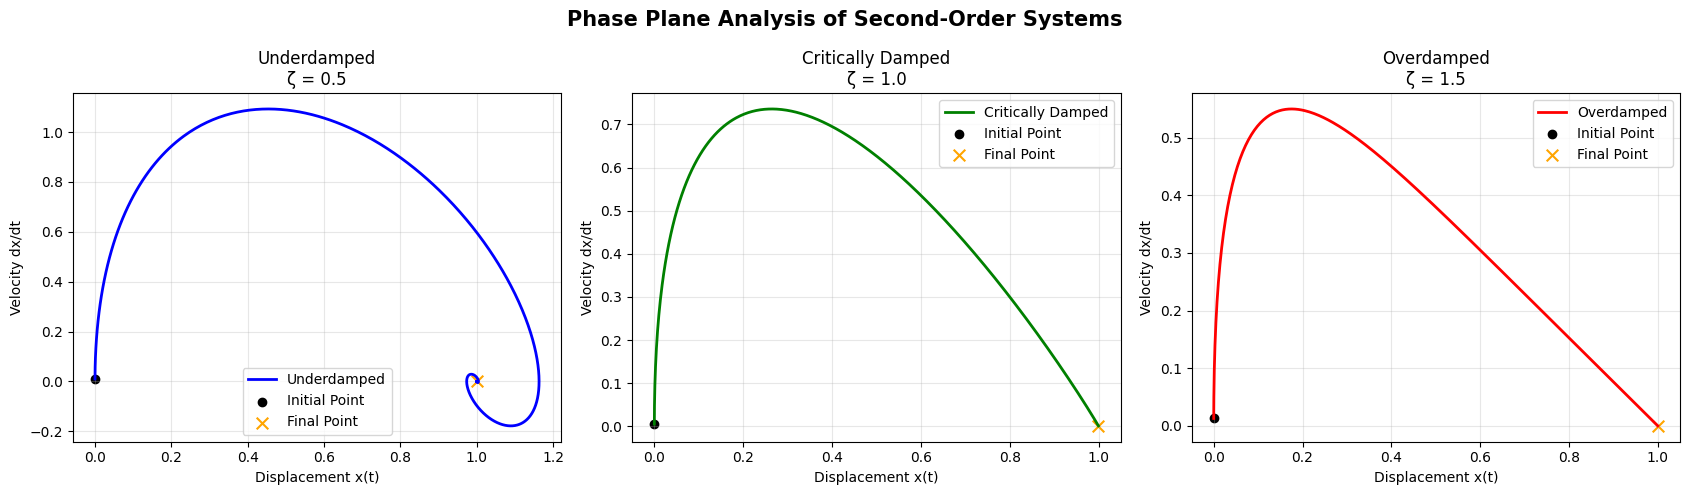

PHASE PLANE SIMULATION RESULTS

UNDERDAMPED
---------------------------------------------
Damping Ratio: 0.5
Final Displacement: 1.0000
Final Velocity: -0.000105
Maximum Velocity: 1.0926
Minimum Velocity: -0.1781

CRITICALLY DAMPED
---------------------------------------------
Damping Ratio: 1.0
Final Displacement: 0.9995
Final Velocity: 0.000910
Maximum Velocity: 0.7358
Minimum Velocity: 0.0009

OVERDAMPED
---------------------------------------------
Damping Ratio: 1.5
Final Displacement: 0.9999
Final Velocity: 0.000041
Maximum Velocity: 0.5498
Minimum Velocity: 0.0000

PHASE PLANE VALIDATION TESTS
Three Damping Cases Test: PASSED
Final Displacement Test: PASSED
Final Velocity Test: PASSED
Damping Classification Test: PASSED

ALL PHASE PLANE TESTS PASSED SUCCESSFULLY!

UNDERDAMPED - SIMULATION


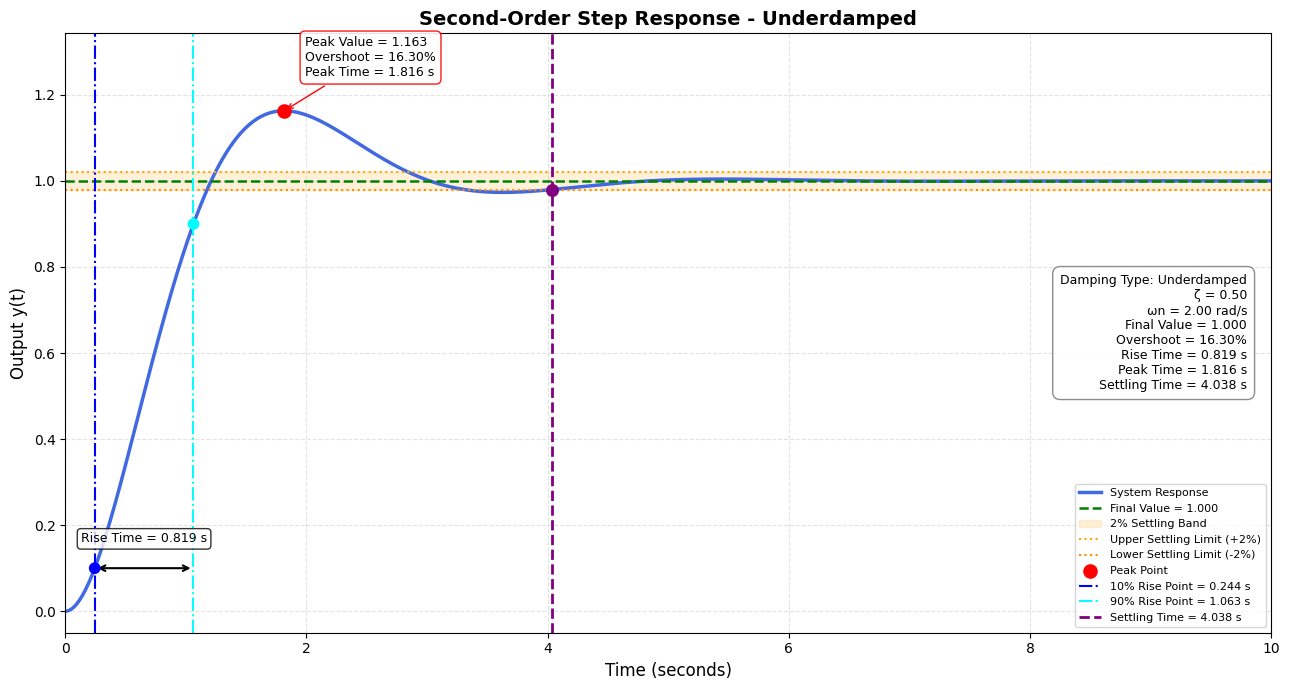


PERFORMANCE METRICS
-----------------------------------
Damping Type: Underdamped
Final Value: 1.0000
Maximum Overshoot: 16.303%
Peak Time: 1.8159079539769885
Peak Value: 1.1630
10% Rise Time Point: 0.2441088676851347
90% Rise Time Point: 1.0629057389577867
Rise Time: 0.818796871272652
Settling Time: 4.0382 s

Validation: PASSED

CRITICALLY DAMPED - SIMULATION


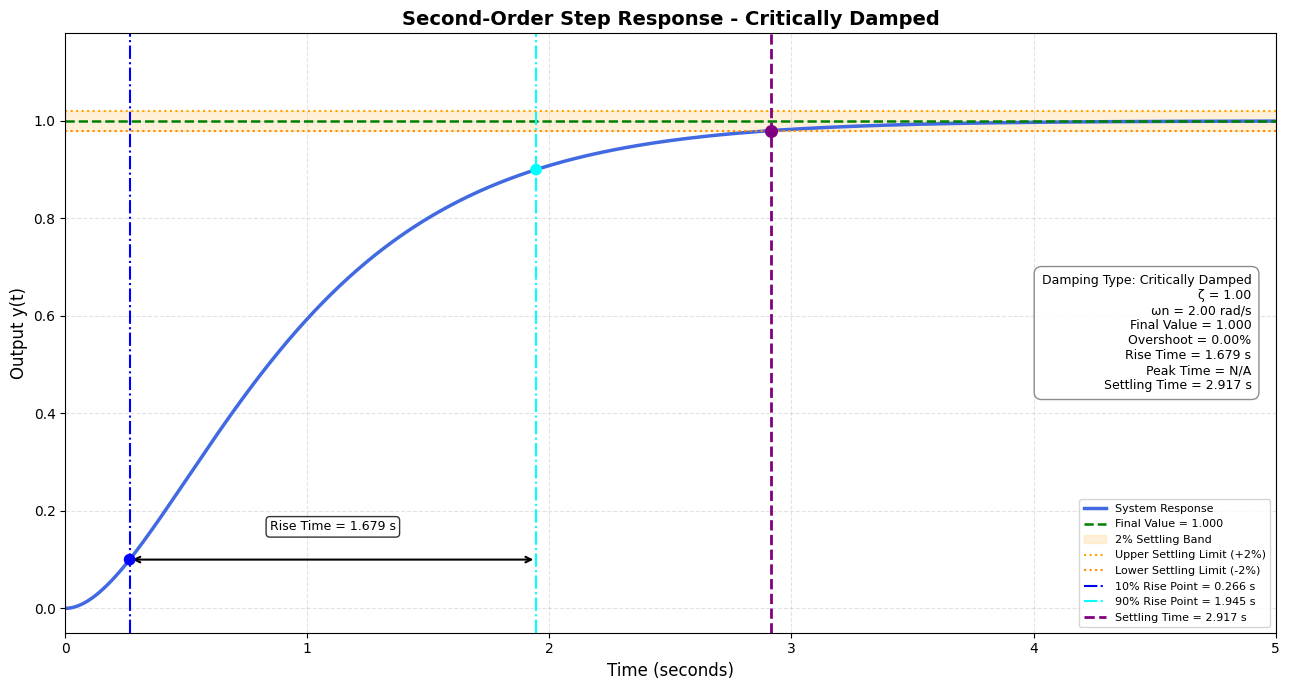


PERFORMANCE METRICS
-----------------------------------
Damping Type: Critically Damped
Final Value: 1.0000
Maximum Overshoot: 0.000%
Peak Time: None
Peak Value: 0.9995
10% Rise Time Point: 0.26590463120623736
90% Rise Time Point: 1.9448612327066643
Rise Time: 1.678956601500427
Settling Time: 2.9170 s

Validation: PASSED

OVERDAMPED - SIMULATION


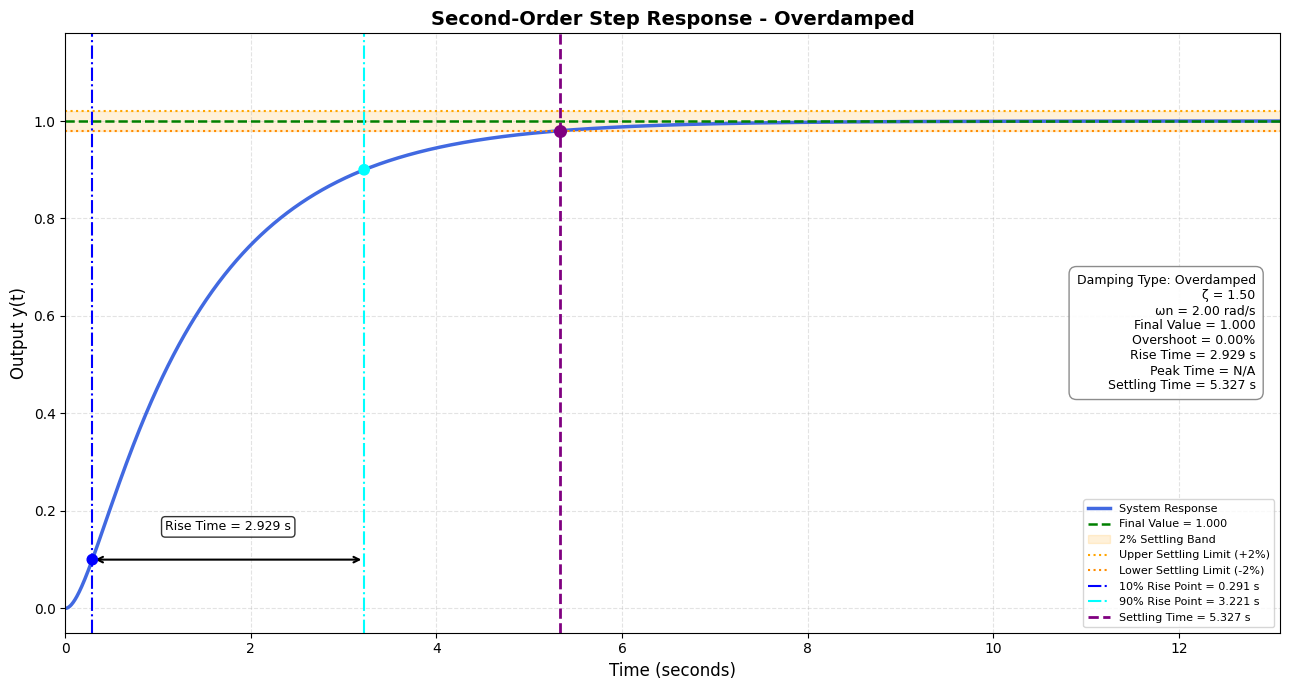


PERFORMANCE METRICS
-----------------------------------
Damping Type: Overdamped
Final Value: 1.0000
Maximum Overshoot: 0.000%
Peak Time: None
Peak Value: 0.9999
10% Rise Time Point: 0.2914174900090384
90% Rise Time Point: 3.2205635359318014
Rise Time: 2.929146045922763
Settling Time: 5.3273 s

Validation: PASSED

ALL THREE DAMPING CASES PASSED SUCCESSFULLY!


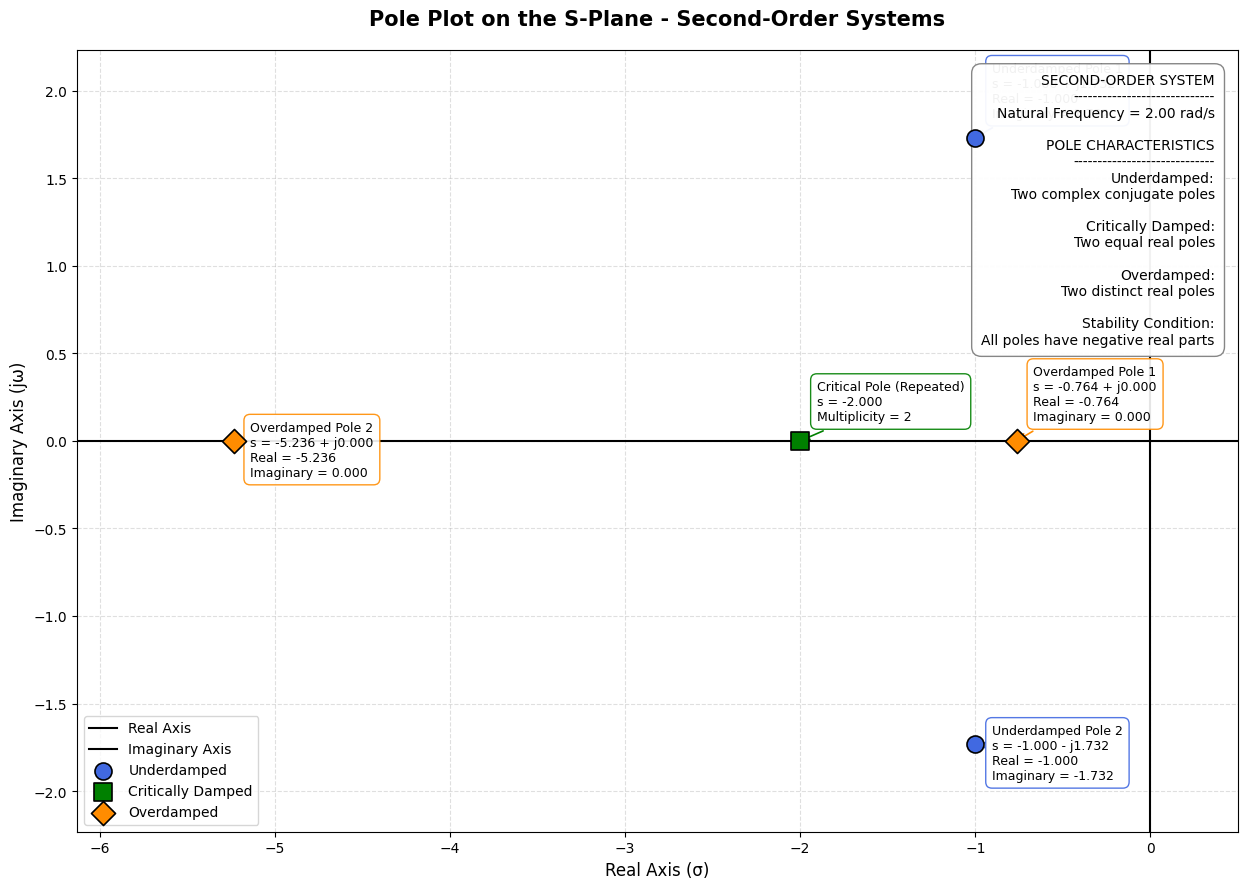


SECOND-ORDER SYSTEM - POLE ANALYSIS

UNDERDAMPED
----------------------------------------
Damping Ratio: 0.5
Pole 1: -1.0000 +1.7321j
Pole 2: -1.0000 -1.7321j

CRITICALLY DAMPED
----------------------------------------
Damping Ratio: 1.0
Pole 1: -2.0000 +0.0000j
Pole 2: -2.0000 +0.0000j

OVERDAMPED
----------------------------------------
Damping Ratio: 1.5
Pole 1: -0.7639 +0.0000j
Pole 2: -5.2361 +0.0000j

System Stability: True

POLE PLOT VALIDATION
Underdamped Test: PASSED
Critically Damped Test: PASSED
Overdamped Test: PASSED
Stability Test: PASSED

ALL POLE PLOT TESTS PASSED SUCCESSFULLY!


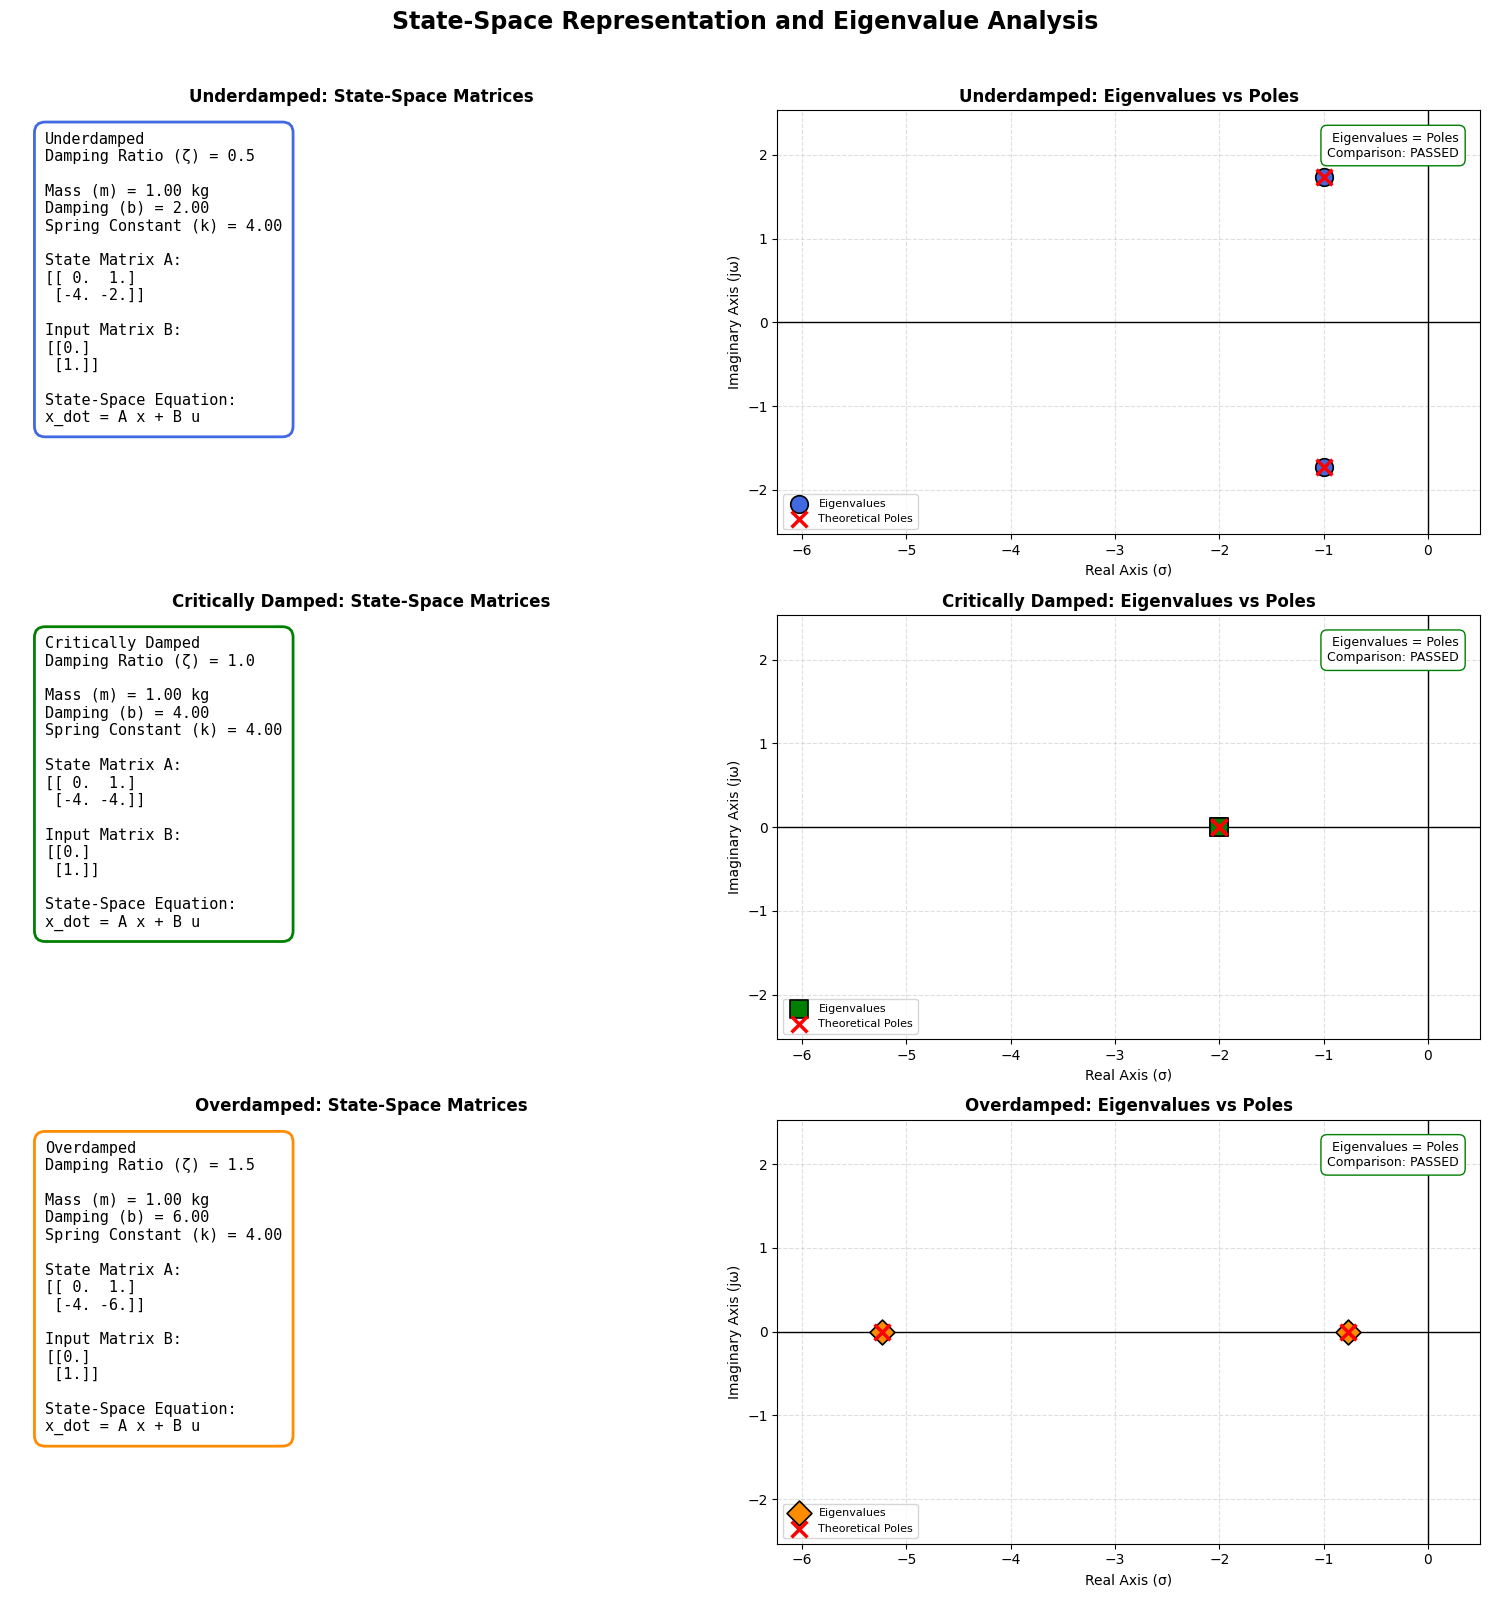


STATE-SPACE MATRICES AND EIGENVALUE ANALYSIS

UNDERDAMPED
---------------------------------------------
Damping Ratio: 0.5
Mass: 1.0
Damping Coefficient: 2.0
Spring Constant: 4.0

A Matrix:
[[ 0.  1.]
 [-4. -2.]]

B Matrix:
[[0.]
 [1.]]

Eigenvalues:
Eigenvalue 1: -1.0000 +1.7321j
Eigenvalue 2: -1.0000 -1.7321j

Theoretical Poles:
Pole 1: -1.0000 +1.7321j
Pole 2: -1.0000 -1.7321j

Eigenvalues Match Poles: True

CRITICALLY DAMPED
---------------------------------------------
Damping Ratio: 1.0
Mass: 1.0
Damping Coefficient: 4.0
Spring Constant: 4.0

A Matrix:
[[ 0.  1.]
 [-4. -4.]]

B Matrix:
[[0.]
 [1.]]

Eigenvalues:
Eigenvalue 1: -2.0000 +0.0000j
Eigenvalue 2: -2.0000 +0.0000j

Theoretical Poles:
Pole 1: -2.0000 +0.0000j
Pole 2: -2.0000 +0.0000j

Eigenvalues Match Poles: True

OVERDAMPED
---------------------------------------------
Damping Ratio: 1.5
Mass: 1.0
Damping Coefficient: 6.0
Spring Constant: 4.0

A Matrix:
[[ 0.  1.]
 [-4. -6.]]

B Matrix:
[[0.]
 [1.]]

Eigenvalues:
Eigen

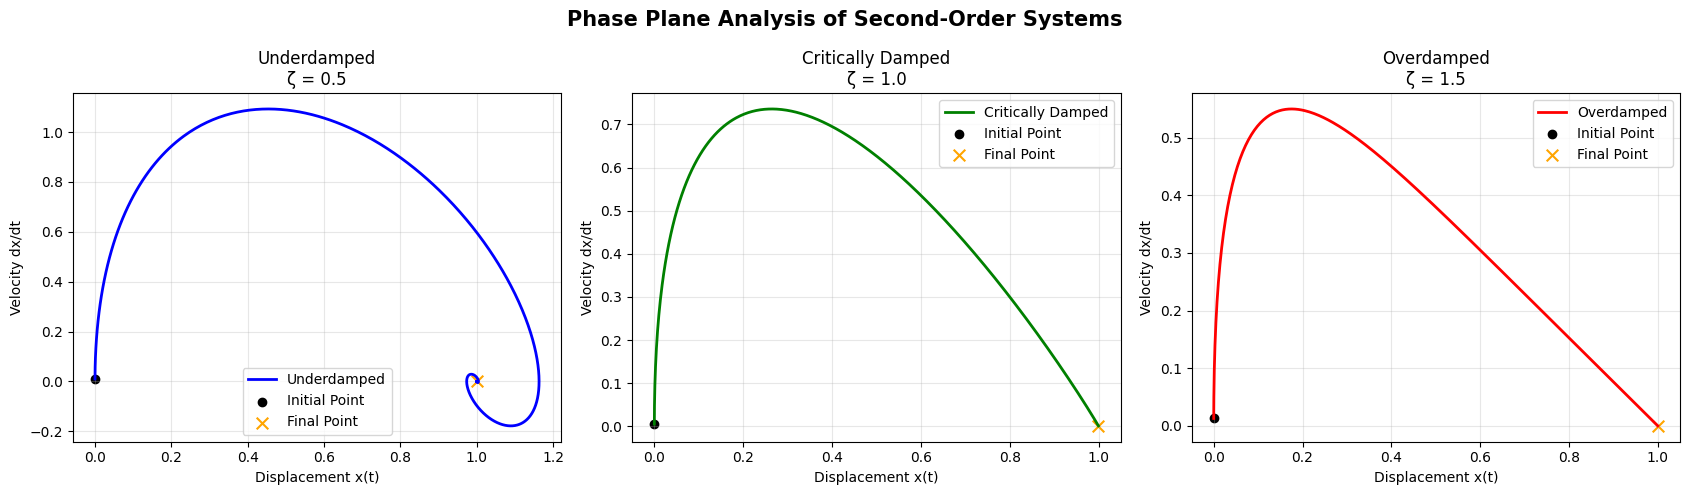

Phase Plane Graph Generated Successfully!


In [30]:

# ============================================================
# MODULE 3: COMPLETE SIMULATION FUNCTIONS
# SECOND-ORDER SYSTEMS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PART 1: CALCULATION FUNCTIONS
# ============================================================

# ------------------------------------------------------------
# 1. SECOND-ORDER STEP RESPONSE
# ------------------------------------------------------------

def calculate_second_order_step_response(K, zeta, omega_n, t, A=1.0):

    if zeta <= 0:
        raise ValueError("Damping Ratio must be positive")

    if omega_n <= 0:
        raise ValueError("Natural Frequency must be positive")

    t = np.asarray(t)

    if zeta < 1:

        omega_d = omega_n * np.sqrt(1 - zeta**2)

        return K * A * (
            1 - np.exp(-zeta * omega_n * t) * (
                np.cos(omega_d * t) +
                (zeta / np.sqrt(1 - zeta**2)) * np.sin(omega_d * t)
            )
        )

    elif np.isclose(zeta, 1.0):

        return K * A * (
            1 - np.exp(-omega_n * t) * (1 + omega_n * t)
        )

    else:

        alpha = np.sqrt(zeta**2 - 1)

        return K * A * (
            1 - (
                (zeta + alpha) * np.exp(-omega_n * (zeta - alpha) * t)
                - (zeta - alpha) * np.exp(-omega_n * (zeta + alpha) * t)
            ) / (2 * alpha)
        )



import numpy as np
import matplotlib.pyplot as plt

def simulate_phase_plane(
    K=1.0,
    omega_n=2.0,
    A=1.0,
    num_points=2000
):
    damping_cases = [
        ("Underdamped", 0.5, "blue"),
        ("Critically Damped", 1.0, "green"),
        ("Overdamped", 1.5, "red")
    ]

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    results = []

    for ax, (name, zeta, color) in zip(axes, damping_cases):

        if zeta > 1:
            slow_rate = omega_n * (
                zeta - np.sqrt(zeta**2 - 1)
            )
            t_end = 10 / slow_rate
        else:
            t_end = 10 / (zeta * omega_n)

        t = np.linspace(0, t_end, num_points)

        # Calculate displacement
        x = calculate_second_order_step_response(
            K, zeta, omega_n, t, A
        )

        # Calculate velocity
        velocity = np.gradient(x, t)

        # Plot phase plane
        ax.plot(
            x,
            velocity,
            color=color,
            linewidth=2,
            label=name
        )

        ax.scatter(
            x[0], velocity[0],
            color="black",
            marker="o",
            label="Initial Point"
        )

        ax.scatter(
            x[-1], velocity[-1],
            color="orange",
            marker="x",
            s=70,
            label="Final Point"
        )

        ax.set_title(f"{name}\nζ = {zeta}")
        ax.set_xlabel("Displacement x(t)")
        ax.set_ylabel("Velocity dx/dt")
        ax.grid(True, alpha=0.3)
        ax.legend()

        results.append({
            "damping_type": name,
            "zeta": zeta,
            "final_displacement": x[-1],
            "final_velocity": velocity[-1],
            "maximum_velocity": np.max(velocity),
            "minimum_velocity": np.min(velocity)
        })

    fig.suptitle(
        "Phase Plane Analysis of Second-Order Systems",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    return results


# Run simulation
phase_results = simulate_phase_plane()


# Display results
print("=" * 65)
print("PHASE PLANE SIMULATION RESULTS")
print("=" * 65)

for result in phase_results:
    print(f"\n{result['damping_type'].upper()}")
    print("-" * 45)
    print(f"Damping Ratio: {result['zeta']}")
    print(
        f"Final Displacement: "
        f"{result['final_displacement']:.4f}"
    )
    print(
        f"Final Velocity: "
        f"{result['final_velocity']:.6f}"
    )
    print(
        f"Maximum Velocity: "
        f"{result['maximum_velocity']:.4f}"
    )
    print(
        f"Minimum Velocity: "
        f"{result['minimum_velocity']:.4f}"
    )


# Validation Tests
print("\n" + "=" * 65)
print("PHASE PLANE VALIDATION TESTS")
print("=" * 65)

assert len(phase_results) == 3
print("Three Damping Cases Test: PASSED")

for result in phase_results:
    assert np.isclose(
        result["final_displacement"], 1.0, atol=0.01
    )

print("Final Displacement Test: PASSED")

for result in phase_results:
    assert abs(result["final_velocity"]) < 0.01

print("Final Velocity Test: PASSED")

assert phase_results[0]["zeta"] < 1
assert phase_results[1]["zeta"] == 1
assert phase_results[2]["zeta"] > 1

print("Damping Classification Test: PASSED")

print("\nALL PHASE PLANE TESTS PASSED SUCCESSFULLY!")


# ------------------------------------------------------------
# 2. STATE-SPACE MATRICES
# ------------------------------------------------------------

def calculate_state_space(m, b, k):

    if m <= 0:
        raise ValueError("Mass must be positive")

    if b < 0:
        raise ValueError("Damping Coefficient must be non-negative")

    if k <= 0:
        raise ValueError("Spring Constant must be positive")

    A = np.array([
        [0, 1],
        [-k/m, -b/m]
    ])

    B = np.array([
        [0],
        [1/m]
    ])

    return A, B


# ------------------------------------------------------------
# 3. EIGENVALUES
# ------------------------------------------------------------

def calculate_eigenvalues(A):

    return np.linalg.eigvals(A)


# ------------------------------------------------------------
# 4. THEORETICAL POLES
# ------------------------------------------------------------

def calculate_poles(zeta, omega_n):

    if zeta <= 0:
        raise ValueError("Damping Ratio must be positive")

    if omega_n <= 0:
        raise ValueError("Natural Frequency must be positive")

    if zeta < 1:

        return (
            -zeta * omega_n
            + omega_n * np.sqrt(1 - zeta**2) * 1j,

            -zeta * omega_n
            - omega_n * np.sqrt(1 - zeta**2) * 1j
        )

    elif zeta == 1:

        return (
            -zeta * omega_n,
            -zeta * omega_n
        )

    else:

        return (
            -zeta * omega_n
            + omega_n * np.sqrt(zeta**2 - 1),

            -zeta * omega_n
            - omega_n * np.sqrt(zeta**2 - 1)
        )


# ============================================================
# PART 2: HELPER FUNCTION
# LINEAR INTERPOLATION
# ============================================================

def interpolate_crossing(t1, y1, t2, y2, target):

    if np.isclose(y2, y1):
        return float(t2)

    return float(
        t1 + (target - y1) * (t2 - t1) / (y2 - y1)
    )


# ============================================================
# PART 3: SECOND-ORDER TIME RESPONSE SIMULATION
# ============================================================

def simulate_second_order(
    K,
    zeta,
    omega_n,
    A=1.0,
    t_end=None,
    num_points=2000
):

    # --------------------------------------------------------
    # INPUT VALIDATION
    # --------------------------------------------------------

    if K <= 0:
        raise ValueError("K must be positive")

    if A <= 0:
        raise ValueError("Input amplitude A must be positive")

    if zeta <= 0:
        raise ValueError("Damping ratio must be positive")

    if omega_n <= 0:
        raise ValueError("Natural frequency must be positive")

    if num_points < 2:
        raise ValueError("Number of points must be at least 2")

    # --------------------------------------------------------
    # AUTOMATIC SIMULATION TIME
    # --------------------------------------------------------

    if t_end is None:

        if zeta > 1:

            slow_pole_rate = omega_n * (
                zeta - np.sqrt(zeta**2 - 1)
            )

            t_end = 10 / slow_pole_rate

        else:

            t_end = 10 / (zeta * omega_n)

    if t_end <= 0:
        raise ValueError("Simulation time must be positive")

    # --------------------------------------------------------
    # GENERATE TIME AND SYSTEM RESPONSE
    # --------------------------------------------------------

    t = np.linspace(0, t_end, num_points)

    y = np.asarray(
        calculate_second_order_step_response(
            K, zeta, omega_n, t, A
        ),
        dtype=float
    )

    final_value = K * A

    # --------------------------------------------------------
    # DETERMINE DAMPING TYPE
    # --------------------------------------------------------

    if np.isclose(zeta, 1.0):
        damping_type = "Critically Damped"

    elif zeta < 1:
        damping_type = "Underdamped"

    else:
        damping_type = "Overdamped"

    # --------------------------------------------------------
    # PERFORMANCE METRICS
    # --------------------------------------------------------

    # 1. Maximum Overshoot and Peak Point

    peak_index = int(np.argmax(y))

    peak_value = float(y[peak_index])
    peak_time = float(t[peak_index])

    overshoot = max(
        0.0,
        (peak_value - final_value) / final_value * 100
    )

    if overshoot >= 0.01:
        peak_time_result = peak_time
    else:
        peak_time_result = None

    # 2. Rise Time (10% to 90%)

    level_10 = 0.10 * final_value
    level_90 = 0.90 * final_value

    indices_10 = np.where(y >= level_10)[0]
    indices_90 = np.where(y >= level_90)[0]

    t_10 = None
    t_90 = None
    rise_time = None

    if len(indices_10) > 0 and len(indices_90) > 0:

        i10 = int(indices_10[0])
        i90 = int(indices_90[0])

        if i10 == 0:
            t_10 = float(t[0])
        else:
            t_10 = interpolate_crossing(
                t[i10 - 1], y[i10 - 1],
                t[i10], y[i10],
                level_10
            )

        if i90 == 0:
            t_90 = float(t[0])
        else:
            t_90 = interpolate_crossing(
                t[i90 - 1], y[i90 - 1],
                t[i90], y[i90],
                level_90
            )

        rise_time = float(t_90 - t_10)

    # 3. Settling Time (2% Criterion)

    tolerance = 0.02 * abs(final_value)

    upper_limit = final_value + tolerance
    lower_limit = final_value - tolerance

    within_band = (
        (y >= lower_limit) &
        (y <= upper_limit)
    )

    outside_indices = np.where(~within_band)[0]

    settling_time = None

    if len(outside_indices) == 0:

        settling_time = 0.0

    elif outside_indices[-1] < len(t) - 1:

        last_outside = int(outside_indices[-1])
        next_inside = last_outside + 1

        if y[last_outside] > upper_limit:
            boundary = upper_limit
        else:
            boundary = lower_limit

        settling_time = interpolate_crossing(
            t[last_outside],
            y[last_outside],
            t[next_inside],
            y[next_inside],
            boundary
        )

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(13, 7))

    ax.plot(
        t, y,
        color="royalblue",
        linewidth=2.5,
        label="System Response"
    )

    ax.axhline(
        final_value,
        color="green",
        linestyle="--",
        linewidth=1.8,
        label=f"Final Value = {final_value:.3f}"
    )

    ax.axhspan(
        lower_limit,
        upper_limit,
        color="orange",
        alpha=0.15,
        label="2% Settling Band"
    )

    ax.axhline(
        upper_limit,
        color="orange",
        linestyle=":",
        linewidth=1.5,
        label="Upper Settling Limit (+2%)"
    )

    ax.axhline(
        lower_limit,
        color="darkorange",
        linestyle=":",
        linewidth=1.5,
        label="Lower Settling Limit (-2%)"
    )

    # --------------------------------------------------------
    # PEAK POINT AND OVERSHOOT
    # --------------------------------------------------------

    if peak_time_result is not None:

        ax.scatter(
            peak_time,
            peak_value,
            color="red",
            s=90,
            zorder=5,
            label="Peak Point"
        )

        ax.annotate(
            f"Peak Value = {peak_value:.3f}\n"
            f"Overshoot = {overshoot:.2f}%\n"
            f"Peak Time = {peak_time:.3f} s",

            xy=(peak_time, peak_value),
            xytext=(15, 25),
            textcoords="offset points",

            arrowprops=dict(
                arrowstyle="->",
                color="red"
            ),

            fontsize=9,

            bbox=dict(
                boxstyle="round,pad=0.4",
                fc="white",
                ec="red",
                alpha=0.9
            )
        )

    # --------------------------------------------------------
    # RISE TIME MARKERS
    # --------------------------------------------------------

    if t_10 is not None and t_90 is not None:

        ax.axvline(
            t_10,
            color="blue",
            linestyle="-.",
            linewidth=1.5,
            label=f"10% Rise Point = {t_10:.3f} s"
        )

        ax.axvline(
            t_90,
            color="cyan",
            linestyle="-.",
            linewidth=1.5,
            label=f"90% Rise Point = {t_90:.3f} s"
        )

        ax.scatter(
            [t_10, t_90],
            [level_10, level_90],
            color=["blue", "cyan"],
            s=55,
            zorder=5
        )

        ax.annotate(
            "",
            xy=(t_90, level_10),
            xytext=(t_10, level_10),
            arrowprops=dict(
                arrowstyle="<->",
                color="black",
                linewidth=1.5
            )
        )

        ax.text(
            (t_10 + t_90) / 2,
            level_10 + 0.06 * abs(final_value),
            f"Rise Time = {rise_time:.3f} s",
            ha="center",
            fontsize=9,
            bbox=dict(
                boxstyle="round",
                fc="white",
                alpha=0.8
            )
        )

    # --------------------------------------------------------
    # SETTLING TIME MARKER
    # --------------------------------------------------------

    if settling_time is not None:

        ax.axvline(
            settling_time,
            color="purple",
            linestyle="--",
            linewidth=2,
            label=f"Settling Time = {settling_time:.3f} s"
        )

        ax.scatter(
            settling_time,
            np.interp(settling_time, t, y),
            color="purple",
            s=70,
            zorder=5
        )

    # --------------------------------------------------------
    # METRICS INFORMATION BOX
    # --------------------------------------------------------

    rise_text = (
        f"{rise_time:.3f} s"
        if rise_time is not None else "N/A"
    )

    peak_text = (
        f"{peak_time_result:.3f} s"
        if peak_time_result is not None else "N/A"
    )

    settling_text = (
        f"{settling_time:.3f} s"
        if settling_time is not None else "N/A"
    )

    metrics_text = (
        f"Damping Type: {damping_type}\n"
        f"ζ = {zeta:.2f}\n"
        f"ωn = {omega_n:.2f} rad/s\n"
        f"Final Value = {final_value:.3f}\n"
        f"Overshoot = {overshoot:.2f}%\n"
        f"Rise Time = {rise_text}\n"
        f"Peak Time = {peak_text}\n"
        f"Settling Time = {settling_text}"
    )

    ax.text(
        0.98,
        0.50,
        metrics_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="center",
        horizontalalignment="right",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )

    # --------------------------------------------------------
    # GRAPH FORMATTING
    # --------------------------------------------------------

    ax.set_xlabel("Time (seconds)", fontsize=12)
    ax.set_ylabel("Output y(t)", fontsize=12)

    ax.set_title(
        f"Second-Order Step Response - {damping_type}",
        fontsize=14,
        fontweight="bold"
    )

    ax.grid(True, linestyle="--", alpha=0.35)

    ax.legend(loc="lower right", fontsize=8)

    ax.set_xlim(0, t_end)

    ax.set_ylim(
        min(0, np.min(y) - 0.05 * abs(final_value)),
        max(upper_limit, np.max(y) + 0.18 * abs(final_value))
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # RETURN DATA FOR WEBSITE INTEGRATION
    # --------------------------------------------------------

    return {
        "time": t.tolist(),
        "output": y.tolist(),
        "damping_type": damping_type,
        "K": float(K),
        "zeta": float(zeta),
        "omega_n": float(omega_n),
        "input_amplitude": float(A),
        "final_value": float(final_value),
        "overshoot_percent": float(overshoot),
        "peak_time": peak_time_result,
        "peak_value": peak_value,
        "rise_time": rise_time,
        "t_10": t_10,
        "t_90": t_90,
        "settling_time": settling_time,
        "upper_settling_limit": float(upper_limit),
        "lower_settling_limit": float(lower_limit)
    }


# ============================================================
# PART 4: TEST SECOND-ORDER TIME RESPONSE
# ============================================================

test_cases = [

    {
        "name": "Underdamped",
        "zeta": 0.5,
        "expected_overshoot": 16.3
    },

    {
        "name": "Critically Damped",
        "zeta": 1.0,
        "expected_overshoot": 0.0
    },

    {
        "name": "Overdamped",
        "zeta": 1.5,
        "expected_overshoot": 0.0
    }

]

simulation_results = {}

for case in test_cases:

    print("\n" + "=" * 55)
    print(f"{case['name'].upper()} - SIMULATION")
    print("=" * 55)

    result = simulate_second_order(
        K=1.0,
        zeta=case["zeta"],
        omega_n=2.0,
        A=1.0,
        num_points=2000
    )

    simulation_results[case["name"]] = result

    print("\nPERFORMANCE METRICS")
    print("-" * 35)

    print("Damping Type:", result["damping_type"])
    print(f"Final Value: {result['final_value']:.4f}")

    print(
        f"Maximum Overshoot: "
        f"{result['overshoot_percent']:.3f}%"
    )

    print("Peak Time:", result["peak_time"])
    print(f"Peak Value: {result['peak_value']:.4f}")
    print("10% Rise Time Point:", result["t_10"])
    print("90% Rise Time Point:", result["t_90"])
    print("Rise Time:", result["rise_time"])

    if result["settling_time"] is None:
        print("Settling Time: Not reached within simulation time")
    else:
        print(f"Settling Time: {result['settling_time']:.4f} s")

    # VALIDATION

    assert result["damping_type"] == case["name"]

    assert abs(result["final_value"] - 1.0) < 0.001

    assert abs(
        result["overshoot_percent"] -
        case["expected_overshoot"]
    ) < 0.5

    assert result["rise_time"] is not None
    assert result["settling_time"] is not None

    if case["zeta"] < 1:
        assert result["peak_time"] is not None
    else:
        assert result["peak_time"] is None

    print("\nValidation: PASSED")


print("\n" + "=" * 55)
print("ALL THREE DAMPING CASES PASSED SUCCESSFULLY!")
print("=" * 55)


# ============================================================
# PART 5: POLE PLOT ON THE S-PLANE
# ============================================================

def simulate_pole_plot(omega_n=2.0):

    # INPUT VALIDATION

    if omega_n <= 0:
        raise ValueError("Natural Frequency must be positive")

    # DEFINE DAMPING CASES

    damping_cases = [

        {
            "name": "Underdamped",
            "zeta": 0.5,
            "color": "royalblue",
            "marker": "o"
        },

        {
            "name": "Critically Damped",
            "zeta": 1.0,
            "color": "green",
            "marker": "s"
        },

        {
            "name": "Overdamped",
            "zeta": 1.5,
            "color": "darkorange",
            "marker": "D"
        }

    ]

    pole_results = {}

    all_real_parts = []
    all_imag_parts = []

    # CALCULATE POLES

    for case in damping_cases:

        zeta = case["zeta"]

        poles = np.asarray(
            calculate_poles(zeta, omega_n),
            dtype=complex
        )

        pole_results[case["name"]] = {

            "zeta": float(zeta),

            "poles": [
                {
                    "real": float(np.real(pole)),
                    "imaginary": float(np.imag(pole))
                }
                for pole in poles
            ]

        }

        all_real_parts.extend(np.real(poles))
        all_imag_parts.extend(np.imag(poles))

    # GRAPH LIMITS

    x_min = min(all_real_parts)
    x_max = max(all_real_parts)

    y_max = max(abs(np.array(all_imag_parts)))

    x_margin = 0.20 * (x_max - x_min)

    if x_margin == 0:
        x_margin = 1.0

    y_margin = max(0.5, 0.25 * y_max)

    # CREATE FIGURE

    fig, ax = plt.subplots(figsize=(14, 9))

    ax.axhline(
        y=0,
        color="black",
        linewidth=1.5,
        label="Real Axis"
    )

    ax.axvline(
        x=0,
        color="black",
        linewidth=1.5,
        label="Imaginary Axis"
    )

    annotation_offsets = {

        "Underdamped": [(12, 15), (12, -25)],

        "Critically Damped": [(12, 15), (12, -25)],

        "Overdamped": [(12, 15), (12, -25)]

    }

    # PLOT AND ANNOTATE POLES

    for case in damping_cases:

        name = case["name"]
        zeta = case["zeta"]

        poles = [
            complex(pole["real"], pole["imaginary"])
            for pole in pole_results[name]["poles"]
        ]

        for index, pole in enumerate(poles):

            real_part = float(np.real(pole))
            imag_part = float(np.imag(pole))

            if np.isclose(zeta, 1.0) and index == 1:
                continue

            ax.scatter(
                real_part,
                imag_part,
                color=case["color"],
                marker=case["marker"],
                s=150,
                edgecolors="black",
                linewidths=1.2,
                zorder=5,
                label=name if index == 0 else None
            )

            offset = annotation_offsets[name][index]

            if np.isclose(zeta, 1.0):

                annotation = (
                    "Critical Pole (Repeated)\n"
                    f"s = {real_part:.3f}\n"
                    "Multiplicity = 2"
                )

            else:

                sign = "+" if imag_part >= 0 else "-"

                annotation = (
                    f"{name} Pole {index + 1}\n"
                    f"s = {real_part:.3f} "
                    f"{sign} j{abs(imag_part):.3f}\n"
                    f"Real = {real_part:.3f}\n"
                    f"Imaginary = {imag_part:.3f}"
                )

            ax.annotate(
                annotation,
                xy=(real_part, imag_part),
                xytext=offset,
                textcoords="offset points",
                fontsize=9,
                arrowprops=dict(
                    arrowstyle="->",
                    color=case["color"],
                    linewidth=1.2
                ),
                bbox=dict(
                    boxstyle="round,pad=0.5",
                    facecolor="white",
                    edgecolor=case["color"],
                    alpha=0.9
                )
            )

    # SYSTEM INFORMATION BOX

    information_text = (

        "SECOND-ORDER SYSTEM\n"
        "-----------------------------\n"
        f"Natural Frequency = {omega_n:.2f} rad/s\n\n"

        "POLE CHARACTERISTICS\n"
        "-----------------------------\n"
        "Underdamped:\n"
        "Two complex conjugate poles\n\n"

        "Critically Damped:\n"
        "Two equal real poles\n\n"

        "Overdamped:\n"
        "Two distinct real poles\n\n"

        "Stability Condition:\n"
        "All poles have negative real parts"

    )

    ax.text(
        0.98,
        0.97,
        information_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor="white",
            edgecolor="gray",
            alpha=0.95
        )
    )

    # GRAPH FORMATTING

    ax.set_title(
        "Pole Plot on the S-Plane - Second-Order Systems",
        fontsize=15,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel("Real Axis (σ)", fontsize=12)
    ax.set_ylabel("Imaginary Axis (jω)", fontsize=12)

    ax.set_xlim(
        x_min - x_margin,
        max(0.5, x_max + x_margin)
    )

    ax.set_ylim(
        -y_max - y_margin,
        y_max + y_margin
    )

    ax.grid(True, linestyle="--", alpha=0.4)

    ax.legend(loc="lower left", fontsize=10)

    ax.set_aspect("equal", adjustable="box")

    plt.tight_layout()
    plt.show()

    # RETURN DATA

    return {

        "natural_frequency": float(omega_n),

        "pole_results": pole_results,

        "stable": all(real < 0 for real in all_real_parts)

    }


# ============================================================
# PART 6: RUN POLE PLOT SIMULATION
# ============================================================

pole_simulation_results = simulate_pole_plot(
    omega_n=2.0
)

print("\n" + "=" * 60)
print("SECOND-ORDER SYSTEM - POLE ANALYSIS")
print("=" * 60)

for damping_type, data in pole_simulation_results["pole_results"].items():

    print(f"\n{damping_type.upper()}")
    print("-" * 40)

    print("Damping Ratio:", data["zeta"])

    for index, pole in enumerate(data["poles"]):

        print(
            f"Pole {index + 1}: "
            f"{pole['real']:.4f} "
            f"{pole['imaginary']:+.4f}j"
        )

print("\nSystem Stability:", pole_simulation_results["stable"])


# ============================================================
# PART 7: POLE PLOT VALIDATION
# ============================================================

print("\n" + "=" * 60)
print("POLE PLOT VALIDATION")
print("=" * 60)

# Test 1: Underdamped

under = pole_simulation_results["pole_results"]["Underdamped"]["poles"]

assert len(under) == 2
assert np.isclose(under[0]["real"], -1.0)
assert np.isclose(abs(under[0]["imaginary"]), np.sqrt(3))
assert np.isclose(under[0]["real"], under[1]["real"])
assert np.isclose(under[0]["imaginary"], -under[1]["imaginary"])

print("Underdamped Test: PASSED")


# Test 2: Critically Damped

critical = pole_simulation_results["pole_results"]["Critically Damped"]["poles"]

assert len(critical) == 2
assert np.isclose(critical[0]["real"], -2.0)
assert np.isclose(critical[1]["real"], -2.0)
assert np.isclose(critical[0]["imaginary"], 0.0)
assert np.isclose(critical[1]["imaginary"], 0.0)

print("Critically Damped Test: PASSED")


# Test 3: Overdamped

over = pole_simulation_results["pole_results"]["Overdamped"]["poles"]

expected_poles = sorted([
    -3 + np.sqrt(5),
    -3 - np.sqrt(5)
])

actual_poles = sorted(pole["real"] for pole in over)

assert len(over) == 2
assert np.allclose(actual_poles, expected_poles)
assert all(np.isclose(pole["imaginary"], 0.0) for pole in over)

print("Overdamped Test: PASSED")


# Test 4: Stability

assert pole_simulation_results["stable"] is True

assert all(
    pole["real"] < 0
    for data in pole_simulation_results["pole_results"].values()
    for pole in data["poles"]
)

print("Stability Test: PASSED")

print("\n" + "=" * 60)
print("ALL POLE PLOT TESTS PASSED SUCCESSFULLY!")
print("=" * 60)


# ============================================================
# PART 8: STATE-SPACE MATRICES AND EIGENVALUES SIMULATION
# ============================================================

def simulate_state_space_eigenvalues(m=1.0, k=4.0):

    # INPUT VALIDATION

    if m <= 0:
        raise ValueError("Mass must be positive")

    if k <= 0:
        raise ValueError("Spring Constant must be positive")

    # DEFINE SYSTEM PARAMETERS

    damping_cases = [

        {
            "name": "Underdamped",
            "zeta": 0.5,
            "color": "royalblue",
            "marker": "o"
        },

        {
            "name": "Critically Damped",
            "zeta": 1.0,
            "color": "green",
            "marker": "s"
        },

        {
            "name": "Overdamped",
            "zeta": 1.5,
            "color": "darkorange",
            "marker": "D"
        }

    ]

    omega_n = np.sqrt(k / m)

    results = {}

    # CALCULATE MATRICES AND EIGENVALUES

    for case in damping_cases:

        name = case["name"]
        zeta = case["zeta"]

        b = 2 * zeta * np.sqrt(m * k)

        A, B = calculate_state_space(m, b, k)

        eigenvalues = calculate_eigenvalues(A)

        theoretical_poles = calculate_poles(zeta, omega_n)

        eigenvalues = np.asarray(eigenvalues, dtype=complex)

        theoretical_poles = np.asarray(
            theoretical_poles,
            dtype=complex
        )

        eigenvalues_sorted = np.sort_complex(eigenvalues)
        poles_sorted = np.sort_complex(theoretical_poles)

        match = np.allclose(
            eigenvalues_sorted,
            poles_sorted,
            atol=1e-8
        )

        results[name] = {

            "zeta": float(zeta),

            "mass": float(m),

            "damping_coefficient": float(b),

            "spring_constant": float(k),

            "A_matrix": A.tolist(),

            "B_matrix": B.tolist(),

            "eigenvalues": [
                {
                    "real": float(np.real(value)),
                    "imaginary": float(np.imag(value))
                }
                for value in eigenvalues
            ],

            "theoretical_poles": [
                {
                    "real": float(np.real(value)),
                    "imaginary": float(np.imag(value))
                }
                for value in theoretical_poles
            ],

            "eigenvalues_match_poles": bool(match)

        }

    # --------------------------------------------------------
    # CREATE VISUALIZATION
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        3,
        2,
        figsize=(15, 16)
    )

    fig.suptitle(
        "State-Space Representation and Eigenvalue Analysis",
        fontsize=17,
        fontweight="bold",
        y=0.995
    )

    all_real = [
        value["real"]
        for data in results.values()
        for value in data["eigenvalues"]
    ]

    all_imag = [
        value["imaginary"]
        for data in results.values()
        for value in data["eigenvalues"]
    ]

    x_min = min(all_real) - 1
    x_max = 0.5

    y_max = max(abs(np.array(all_imag))) + 0.8

    # DISPLAY MATRICES AND EIGENVALUES

    for row, case in enumerate(damping_cases):

        name = case["name"]
        data = results[name]

        A = np.array(data["A_matrix"])
        B = np.array(data["B_matrix"])

        # LEFT PANEL: STATE-SPACE MATRICES

        ax_matrix = axes[row, 0]

        ax_matrix.axis("off")

        matrix_text = (

            f"{name}\n"
            f"Damping Ratio (ζ) = {data['zeta']}\n\n"

            f"Mass (m) = {m:.2f} kg\n"
            f"Damping (b) = {data['damping_coefficient']:.2f}\n"
            f"Spring Constant (k) = {k:.2f}\n\n"

            "State Matrix A:\n"
            f"{np.array2string(A, precision=3)}\n\n"

            "Input Matrix B:\n"
            f"{np.array2string(B, precision=3)}\n\n"

            "State-Space Equation:\n"
            "x_dot = A x + B u"

        )

        ax_matrix.text(
            0.05,
            0.95,
            matrix_text,
            transform=ax_matrix.transAxes,
            fontsize=11,
            verticalalignment="top",
            family="monospace",
            bbox=dict(
                boxstyle="round,pad=0.7",
                facecolor="white",
                edgecolor=case["color"],
                linewidth=2
            )
        )

        ax_matrix.set_title(
            f"{name}: State-Space Matrices",
            fontsize=12,
            fontweight="bold"
        )

        # RIGHT PANEL: EIGENVALUES VS THEORETICAL POLES

        ax_eigen = axes[row, 1]

        ax_eigen.axhline(
            0,
            color="black",
            linewidth=1
        )

        ax_eigen.axvline(
            0,
            color="black",
            linewidth=1
        )

        eigenvalues = data["eigenvalues"]
        poles = data["theoretical_poles"]

        # Plot Eigenvalues

        for index, value in enumerate(eigenvalues):

            real_part = value["real"]
            imag_part = value["imaginary"]

            ax_eigen.scatter(
                real_part,
                imag_part,
                color=case["color"],
                marker=case["marker"],
                s=160,
                edgecolors="black",
                linewidths=1.2,
                zorder=5,
                label="Eigenvalues" if index == 0 else None
            )

        # Plot Theoretical Poles

        for index, value in enumerate(poles):

            ax_eigen.scatter(
                value["real"],
                value["imaginary"],
                color="red",
                marker="x",
                s=130,
                linewidths=2.5,
                zorder=6,
                label="Theoretical Poles" if index == 0 else None
            )

        # COMPARISON RESULT

        comparison_text = (

            "Eigenvalues = Poles\n"
            "Comparison: PASSED"

            if data["eigenvalues_match_poles"]

            else

            "Eigenvalues != Poles\n"
            "Comparison: FAILED"

        )

        ax_eigen.text(
            0.97,
            0.95,
            comparison_text,
            transform=ax_eigen.transAxes,
            ha="right",
            va="top",
            fontsize=9,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="white",
                edgecolor=(
                    "green"
                    if data["eigenvalues_match_poles"]
                    else "red"
                )
            )
        )

        ax_eigen.set_title(
            f"{name}: Eigenvalues vs Poles",
            fontsize=12,
            fontweight="bold"
        )

        ax_eigen.set_xlabel("Real Axis (σ)")
        ax_eigen.set_ylabel("Imaginary Axis (jω)")

        ax_eigen.set_xlim(x_min, x_max)
        ax_eigen.set_ylim(-y_max, y_max)

        ax_eigen.grid(
            True,
            linestyle="--",
            alpha=0.4
        )

        ax_eigen.legend(
            loc="lower left",
            fontsize=8
        )

    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

    # RETURN DATA FOR WEBSITE INTEGRATION

    return {

        "mass": float(m),

        "spring_constant": float(k),

        "natural_frequency": float(omega_n),

        "results": results,

        "all_comparisons_passed": all(
            data["eigenvalues_match_poles"]
            for data in results.values()
        )

    }


# ============================================================
# PART 9: RUN STATE-SPACE SIMULATION
# ============================================================

state_space_results = simulate_state_space_eigenvalues(
    m=1.0,
    k=4.0
)


# ============================================================
# PART 10: DISPLAY STATE-SPACE RESULTS
# ============================================================

print("\n" + "=" * 65)
print("STATE-SPACE MATRICES AND EIGENVALUE ANALYSIS")
print("=" * 65)

for name, data in state_space_results["results"].items():

    print(f"\n{name.upper()}")
    print("-" * 45)

    print("Damping Ratio:", data["zeta"])
    print("Mass:", data["mass"])
    print("Damping Coefficient:", data["damping_coefficient"])
    print("Spring Constant:", data["spring_constant"])

    print("\nA Matrix:")
    print(np.array(data["A_matrix"]))

    print("\nB Matrix:")
    print(np.array(data["B_matrix"]))

    print("\nEigenvalues:")

    for index, value in enumerate(data["eigenvalues"]):

        print(
            f"Eigenvalue {index + 1}: "
            f"{value['real']:.4f} "
            f"{value['imaginary']:+.4f}j"
        )

    print("\nTheoretical Poles:")

    for index, value in enumerate(data["theoretical_poles"]):

        print(
            f"Pole {index + 1}: "
            f"{value['real']:.4f} "
            f"{value['imaginary']:+.4f}j"
        )

    print(
        "\nEigenvalues Match Poles:",
        data["eigenvalues_match_poles"]
    )


# ============================================================
# PART 11: STATE-SPACE VALIDATION TESTS
# ============================================================

print("\n" + "=" * 65)
print("STATE-SPACE VALIDATION TESTS")
print("=" * 65)

# Test 1: Matrix Dimensions

for name, data in state_space_results["results"].items():

    A = np.array(data["A_matrix"])
    B = np.array(data["B_matrix"])

    assert A.shape == (2, 2)
    assert B.shape == (2, 1)

print("Matrix Dimensions Test: PASSED")


# Test 2: State-Space Matrix Values

for name, data in state_space_results["results"].items():

    A = np.array(data["A_matrix"])
    B = np.array(data["B_matrix"])

    expected_A = np.array([
        [0, 1],
        [-4, -data["damping_coefficient"]]
    ])

    expected_B = np.array([
        [0],
        [1]
    ])

    assert np.allclose(A, expected_A)
    assert np.allclose(B, expected_B)

print("State-Space Matrices Test: PASSED")


# Test 3: Eigenvalues Equal Theoretical Poles

for name, data in state_space_results["results"].items():

    assert data["eigenvalues_match_poles"] is True

print("Eigenvalues vs Poles Test: PASSED")


# Test 4: Stability

for name, data in state_space_results["results"].items():

    assert all(
        value["real"] < 0
        for value in data["eigenvalues"]
    )

print("Stability Test: PASSED")


# Test 5: All Comparisons

assert state_space_results["all_comparisons_passed"] is True

print("All Comparisons Test: PASSED")


print("\n" + "=" * 65)
print("ALL STATE-SPACE TESTS PASSED SUCCESSFULLY!")
print("=" * 65)


# ============================================================
# MODULE 3: ALL SIMULATIONS COMPLETED
# ============================================================

print("\n" + "=" * 65)
print("MODULE 3: ALL SIMULATIONS COMPLETED SUCCESSFULLY!")
print("=" * 65)

%matplotlib inline

import matplotlib.pyplot as plt

phase_results = simulate_phase_plane()

print("Phase Plane Graph Generated Successfully!")